In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch
torch.set_default_tensor_type(torch.DoubleTensor)
torch.set_default_dtype(torch.float64)

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem2
import optimiser_problem2_new as optimiser_problem2
from math import factorial
import pickle
from itertools import product

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
np.random.seed(20250524)
dim = 2
order = 8
trunc_lev = order
num_elements = dim**(order+1) - 1

with open('W_sig_1.pkl', 'rb') as f:
    W_sig = pickle.load(f)
    f.close()
    
with open('LF_experiment_1.pkl', 'rb') as f:
    LF = pickle.load(f)
    f.close()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()

F = 2*np.ones(num_elements)
    
#env = problem2.environment(**params)
F = ta.sig_to_tensor(F, dim, order)

In [3]:
F

Tensor([2.0, [2.0, 2.0], [[2.0, 2.0], [2.0, 2.0]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]]], [[[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]]], [[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]]]], [[[[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[

In [4]:
LF

array([1.00000000e+02, 2.21000000e+02, 2.01000000e+02, 5.06200000e+02,
       4.42000000e+02, 4.62200000e+02, 4.02000000e+02, 1.22204000e+03,
       1.01240000e+03, 1.07680000e+03, 8.84000000e+02, 1.12124000e+03,
       9.24400000e+02, 9.84800000e+02, 8.04000000e+02, 3.14480800e+03,
       2.44408000e+03, 2.65392000e+03, 2.02480000e+03, 2.79964000e+03,
       2.15360000e+03, 2.34660000e+03, 1.76800000e+03, 2.90144800e+03,
       2.24248000e+03, 2.43952000e+03, 1.84880000e+03, 2.57644000e+03,
       1.96960000e+03, 2.15060000e+03, 1.60800000e+03, 8.70044960e+03,
       6.28961600e+03, 6.99054400e+03, 4.88816000e+03, 7.48199200e+03,
       5.30784000e+03, 5.93716000e+03, 4.04960000e+03, 7.82838400e+03,
       5.59928000e+03, 6.24552000e+03, 4.30720000e+03, 6.69912000e+03,
       4.69320000e+03, 5.27200000e+03, 3.53600000e+03, 8.07417760e+03,
       5.80289600e+03, 6.46206400e+03, 4.48496000e+03, 6.92455200e+03,
       4.87904000e+03, 5.46996000e+03, 3.69760000e+03, 7.25078400e+03,
      

In [5]:
LF = ta.sig_to_tensor(LF, dim, order)

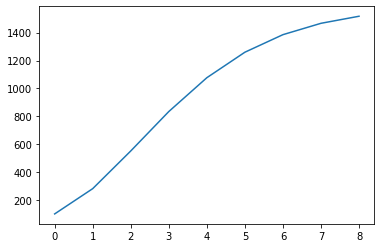

In [14]:
norm = 0

t = 0.2
norm_prog = []

for n in range(order+1):
    coord_list = list(product(range(dim), repeat = n))
    for coord in coord_list:
        x = n - sum(list(coord))
        if n+x-1 < 0:
            h = (2*t)**(0.5*(n+x))/((n+1)**0.25)
        else:
            h = (2*t)**(0.5*(n+x))/((n+1)**0.25*(factorial(n+x-1))**0.5)
        norm += (abs(float(LF.value[n][coord]))*h)
    norm_prog.append(norm)
    
plt.plot(norm_prog)
plt.show()